### KDD · Fase 5: Interpretación y evaluación

Evaluación del modelo final con el grupo de prueba e interpretación de los patrones encontrados.

- **Entradas:** `kdd/data/processed/test_transformed.csv`, `kdd/data/interim/test_clean.csv`, `kdd/models/random_forest.joblib`, `kdd/models/baseline.joblib`, `kdd/data/processed/cv_results.csv`
- **Salidas:**
  - `kdd/data/processed/metrics.csv`: métricas globales
  - `kdd/data/processed/class_report.csv`: métricas por especie
  - `kdd/data/processed/misclassified.csv`: registros mal clasificados
  - `kdd/data/processed/feature_importance.csv`: importancia de las variables
  - `kdd/figures/evaluation_confusion_matrix.png`: matriz de confusión
  - `kdd/figures/interpretation_feature_importance.png`: importancia de las variables

#### Librerías

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

#### Semilla

In [2]:
# Semilla para reproducibilidad. Puede modificarse o eliminarse.
SEED = 1

#### Rutas

Relativas a la carpeta del notebook.

In [3]:
INTERIM_DIR = Path("../data/interim")
PROCESSED_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")
FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

#### Estilo de las figuras

In [4]:
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "legend.frameon": False,
    "font.size": 10,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})

#### Carga de datos y modelos

In [5]:
test = pd.read_csv(PROCESSED_DIR / "test_transformed.csv")
test_clean = pd.read_csv(INTERIM_DIR / "test_clean.csv")

TARGET = "species"
SPECIES = ["Adelie", "Chinstrap", "Gentoo"]

models = {
    "baseline_most_frequent": joblib.load(MODELS_DIR / "baseline.joblib"),
    "random_forest": joblib.load(MODELS_DIR / "random_forest.joblib"),
}
FEATURES = list(models["random_forest"].feature_names_in_)

X_test = test[FEATURES]
y_test = test[TARGET]

print(f"Registros de prueba: {len(X_test)}")
print(y_test.value_counts().to_string())

Registros de prueba: 69
species
Adelie       30
Gentoo       25
Chinstrap    14


#### Predicciones

In [6]:
predictions = {name: model.predict(X_test) for name, model in models.items()}

#### Métricas globales

In [7]:
metrics = pd.DataFrame([
    {
        "modelo": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "f1_macro": f1_score(y_test, y_pred, average="macro"),
        "errores": int((y_pred != y_test).sum()),
        "n": len(y_test),
    }
    for name, y_pred in predictions.items()
]).round(4)
metrics

,modelo,accuracy,balanced_accuracy,f1_macro,errores,n
0,baseline_most_frequent,0.4348,0.3333,0.202,39,69
1,random_forest,1.0000,1.0000,1.000,0,69


#### Validación cruzada frente a prueba

In [8]:
cv_results = pd.read_csv(PROCESSED_DIR / "cv_results.csv")
cv_base = cv_results[cv_results["modelo"] == "baseline_most_frequent"].iloc[0]
cv_rf = cv_results[cv_results["modelo"] == "random_forest"].sort_values("rank").iloc[0]

pd.DataFrame({
    "f1_macro_cv": [cv_base["f1_macro_mean"], cv_rf["f1_macro_mean"]],
    "f1_macro_test": metrics["f1_macro"].values,
}, index=metrics["modelo"]).round(4)

,f1_macro_cv,f1_macro_test
modelo,,
baseline_most_frequent,0.2047,0.202
random_forest,0.9907,1.000


#### Métricas por especie

In [9]:
y_pred = predictions["random_forest"]

class_report = pd.DataFrame(
    classification_report(y_test, y_pred, output_dict=True, zero_division=0)
).T.drop(index="accuracy").round(4)
class_report["support"] = class_report["support"].astype(int)
class_report

,precision,recall,f1-score,support
Adelie,1.0,1.0,1.0,30
Chinstrap,1.0,1.0,1.0,14
Gentoo,1.0,1.0,1.0,25
macro avg,1.0,1.0,1.0,69
weighted avg,1.0,1.0,1.0,69


#### Matriz de confusión

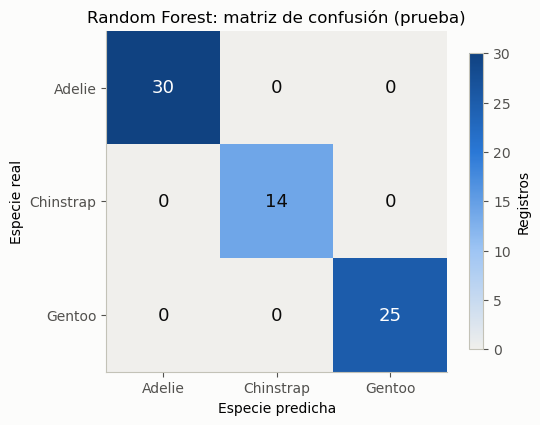

In [10]:
cm = confusion_matrix(y_test, y_pred, labels=SPECIES)
cmap = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#9ec5f4", "#2a78d6", "#104281"])

fig, ax = plt.subplots(figsize=(5.5, 4.8))
im = ax.imshow(cm, cmap=cmap)
for i in range(len(SPECIES)):
    for j in range(len(SPECIES)):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                color="#ffffff" if cm[i, j] > cm.max() / 2 else "#0b0b0b")
ax.set_xticks(range(len(SPECIES)), SPECIES)
ax.set_yticks(range(len(SPECIES)), SPECIES)
ax.set_xlabel("Especie predicha")
ax.set_ylabel("Especie real")
ax.set_title("Random Forest: matriz de confusión (prueba)")
fig.colorbar(im, ax=ax, shrink=0.8, label="Registros")
fig.savefig(FIGURES_DIR / "evaluation_confusion_matrix.png")
plt.show()

#### Registros mal clasificados

In [11]:
model = models["random_forest"]
proba = pd.DataFrame(
    model.predict_proba(X_test),
    columns=[f"prob_{c}" for c in model.classes_],
    index=test.index,
).round(3)

results = pd.concat([test_clean.set_index(test.index), proba], axis=1)
results["predicted"] = y_pred

misclassified = results[results["predicted"] != results[TARGET]]
print(f"Registros mal clasificados: {len(misclassified)} de {len(results)}")
misclassified

Registros mal clasificados: 0 de 69


,row_id,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex,prob_Adelie,prob_Chinstrap,prob_Gentoo,predicted


#### Confianza de las predicciones

Probabilidad máxima asignada en cada predicción.

In [12]:
results["max_prob"] = proba.max(axis=1)
results["correcto"] = results["predicted"] == results[TARGET]

bins = [0, 0.6, 0.8, 0.95, 1.0]
labels = ["< 0.60", "0.60–0.80", "0.80–0.95", "≥ 0.95"]
pd.crosstab(
    pd.cut(results["max_prob"], bins=bins, labels=labels, include_lowest=True),
    results["correcto"].map({True: "correcta", False: "incorrecta"}),
    dropna=False,
).rename_axis(index="probabilidad máxima", columns="predicción")

predicción,correcta
probabilidad máxima,
< 0.60,1
0.60–0.80,1
0.80–0.95,7
≥ 0.95,60


#### Importancia de las variables

- Impureza: calculada por el modelo durante el entrenamiento.
- Permutación: caída del F1 macro en prueba al desordenar cada variable, con 30 repeticiones.

In [13]:
perm = permutation_importance(
    model, X_test, y_test, scoring="f1_macro", n_repeats=30, random_state=SEED, n_jobs=-1,
)

feature_importance = pd.DataFrame({
    "variable": FEATURES,
    "impureza": model.feature_importances_,
    "permutacion_media": perm.importances_mean,
    "permutacion_std": perm.importances_std,
}).sort_values("impureza", ascending=False).round(4).reset_index(drop=True)
feature_importance

,variable,impureza,permutacion_media,permutacion_std
0,culmen_ratio,0.3333,0.2072,0.0438
1,culmen_length_mm,0.1689,0.0186,0.0133
2,flipper_length_mm,0.1638,0.0000,0.0000
3,island_Dream,0.0886,0.0170,0.0123
4,culmen_depth_mm,0.0855,0.0091,0.0077
5,island_Biscoe,0.0747,0.0057,0.0061
6,body_mass_g,0.0690,0.0042,0.0065
7,island_Torgersen,0.0120,0.0160,0.0043
8,sex_FEMALE,0.0023,0.0000,0.0000
9,sex_MALE,0.0018,0.0000,0.0000


#### Gráfica de importancia de las variables

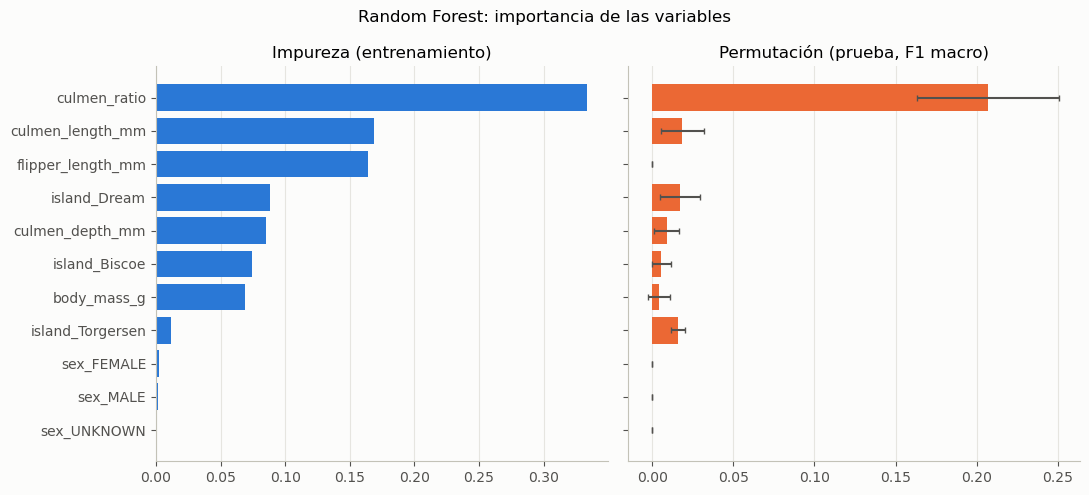

In [14]:
order = feature_importance.sort_values("impureza")
y = np.arange(len(order))

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
axes[0].barh(y, order["impureza"], color="#2a78d6")
axes[0].set_title("Impureza (entrenamiento)")
axes[1].barh(y, order["permutacion_media"], xerr=order["permutacion_std"], color="#eb6834",
             error_kw={"ecolor": "#52514e", "capsize": 2})
axes[1].set_title("Permutación (prueba, F1 macro)")
axes[0].set_yticks(y, order["variable"])
for ax in axes:
    ax.grid(axis="x", color="#e6e5e0")
    ax.set_axisbelow(True)
fig.suptitle("Random Forest: importancia de las variables")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "interpretation_feature_importance.png")
plt.show()

#### Guardado de resultados

In [15]:
metrics.to_csv(PROCESSED_DIR / "metrics.csv", index=False)
class_report.to_csv(PROCESSED_DIR / "class_report.csv")
misclassified.to_csv(PROCESSED_DIR / "misclassified.csv", index=False)
feature_importance.to_csv(PROCESSED_DIR / "feature_importance.csv", index=False)

for path in [
    PROCESSED_DIR / "metrics.csv",
    PROCESSED_DIR / "class_report.csv",
    PROCESSED_DIR / "misclassified.csv",
    PROCESSED_DIR / "feature_importance.csv",
    FIGURES_DIR / "evaluation_confusion_matrix.png",
    FIGURES_DIR / "interpretation_feature_importance.png",
]:
    print(f"Guardado: {path}")

Guardado: ..\data\processed\metrics.csv
Guardado: ..\data\processed\class_report.csv
Guardado: ..\data\processed\misclassified.csv
Guardado: ..\data\processed\feature_importance.csv
Guardado: ..\figures\evaluation_confusion_matrix.png
Guardado: ..\figures\interpretation_feature_importance.png
